# 07 · Model Tuning and Interpretability

**Purpose:** tune the word-level Logistic Regression from notebook 06, then open the model up.

**Questions answered**
- Does hyperparameter tuning (inside the training set only) improve the baseline?
- Which words drive each sentiment class?
- Are the errors related to label uncertainty, and what kinds of tweets are misclassified?
- Does performance hold across airlines?

> **Labels vs predictions:** the descriptive analysis (notebooks 03–05) uses the sentiment labels supplied with the dataset. The models here *predict* those labels from text, for evaluation and for new tweets. Predictions never replace the supplied labels.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from src.config import RANDOM_STATE, SENTIMENT_LABELS
from src.data import load_clean_tweets, split_train_test
from src.evaluation import fit_and_score, score_predictions
from src.modeling import build_word_lr
from src.plotting import PRIMARY_COLOR, SENTIMENT_COLORS, apply_style, save_figure
from src.preprocessing import mask_user_handles

apply_style()
pd.set_option("display.max_colwidth", 140)

df = load_clean_tweets()
print(f"Rows: {len(df):,}")

Rows: 14,481


In [2]:
# Same stratified 80/20 split (random_state=42) as notebooks 06-10; pipelines clean the raw text themselves
train_df, test_df = split_train_test(df)
X_train, y_train = train_df["text"], train_df["airline_sentiment"]
X_test, y_test = test_df["text"], test_df["airline_sentiment"]
print(f"Training tweets: {len(train_df):,} | Test tweets: {len(test_df):,}")

Training tweets: 11,584 | Test tweets: 2,897


## 1. Baseline from notebook 06

Word TF-IDF (1–2 grams) with balanced Logistic Regression and default `C = 1`.

In [3]:
baseline_row = fit_and_score("Baseline word Logistic Regression", build_word_lr(), X_train, y_train, X_test, y_test)
pd.DataFrame([baseline_row]).set_index("model").round(4)

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,
Baseline word Logistic Regression,0.7957,0.7443,0.7491,0.7461,0.7979


## 2. Hyperparameter Tuning with GridSearchCV

The search runs on the **training set only** (3-fold stratified CV, optimising Macro-F1):

| Parameter | Values tried |
|---|---|
| Word n-gram range | (1, 1), (1, 2) |
| Regularisation `C` | 0.25, 0.5, 1, 2, 4 |
| Class weighting | None, balanced |

In [4]:
grid_search = GridSearchCV(
    build_word_lr(),
    param_grid={
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "model__C": [0.25, 0.5, 1, 2, 4],
        "model__class_weight": [None, "balanced"],
    },
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1_macro", n_jobs=-1,
)
grid_search.fit(X_train, y_train)
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best 3-fold CV Macro-F1 (training set): {grid_search.best_score_:.4f}")

(pd.DataFrame(grid_search.cv_results_)
   [["param_tfidf__ngram_range", "param_model__C", "param_model__class_weight", "mean_test_score", "std_test_score"]]
   .sort_values("mean_test_score", ascending=False).head(8).round(4))

Best parameters: {'model__C': 2, 'model__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}
Best 3-fold CV Macro-F1 (training set): 0.7367


,param_tfidf__ngram_range,param_model__C,param_model__class_weight,mean_test_score,std_test_score
15,"(1, 2)",2.00,balanced,0.7367,0.0103
11,"(1, 2)",1.00,balanced,0.7345,0.0102
7,"(1, 2)",0.50,balanced,0.7337,0.0084
19,"(1, 2)",4.00,balanced,0.7329,0.0106
3,"(1, 2)",0.25,balanced,0.7279,0.0068
10,"(1, 1)",1.00,balanced,0.7199,0.0121
17,"(1, 2)",4.00,NaN,0.7196,0.0082
6,"(1, 1)",0.50,balanced,0.7188,0.0093


**Observation:** every top-ranked configuration uses **balanced class weights**; without them the model leans towards the majority Negative class and Macro-F1 is lower. Word pairs (1–2 grams) rank above single words at every `C`.

## 3. Tuned vs Baseline on the Held-Out Test Set

In [5]:
tuned_model = grid_search.best_estimator_
tuned_predictions = tuned_model.predict(X_test)
tuned_row = {"model": "Tuned word Logistic Regression", **score_predictions(y_test, tuned_predictions)}
tuning_comparison = pd.DataFrame([baseline_row, tuned_row]).set_index("model")
display(tuning_comparison.round(4))
print(classification_report(y_test, tuned_predictions, labels=SENTIMENT_LABELS, digits=3))

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,
Baseline word Logistic Regression,0.7957,0.7443,0.7491,0.7461,0.7979
Tuned word Logistic Regression,0.7994,0.7504,0.7472,0.7482,0.8007


              precision    recall  f1-score   support

    Negative      0.877     0.868     0.873      1817
     Neutral      0.615     0.663     0.638       614
    Positive      0.759     0.710     0.734       466

    accuracy                          0.799      2897
   macro avg      0.750     0.747     0.748      2897
weighted avg      0.803     0.799     0.801      2897



**Interpretation:** tuning changes the test scores only slightly. The default configuration was already close to the best in this search space. Confirming that is a valid result; it shows that bigger gains need **better features** (notebook 08), not more tuning.

## 4. Interpretability: Which Words Drive Each Class?

The tuned word-level model is used because its coefficients map directly onto readable words; character n-gram coefficients (notebook 08) are hard to interpret. Positive coefficients push a tweet towards that class.

In [6]:
# The tuned word-level model maps coefficients directly onto readable words
vocabulary = tuned_model.named_steps["tfidf"].get_feature_names_out()
coefficients = tuned_model.named_steps["model"].coef_
classes = list(tuned_model.named_steps["model"].classes_)

top_terms = pd.DataFrame({
    sentiment: vocabulary[np.argsort(coefficients[classes.index(sentiment)])[::-1][:15]]
    for sentiment in SENTIMENT_LABELS
})
top_terms.index = range(1, 16)
top_terms

,Negative,Neutral,Positive
1,not,is there,great
2,delayed,hi,thanks
3,no,can you,awesome
4,hours,can,love
5,worst,is your,amazing
6,your,do you,thank
7,why,any,thx
8,cancelled,dm,appreciate
9,hour,do,best
10,delay,need,the best


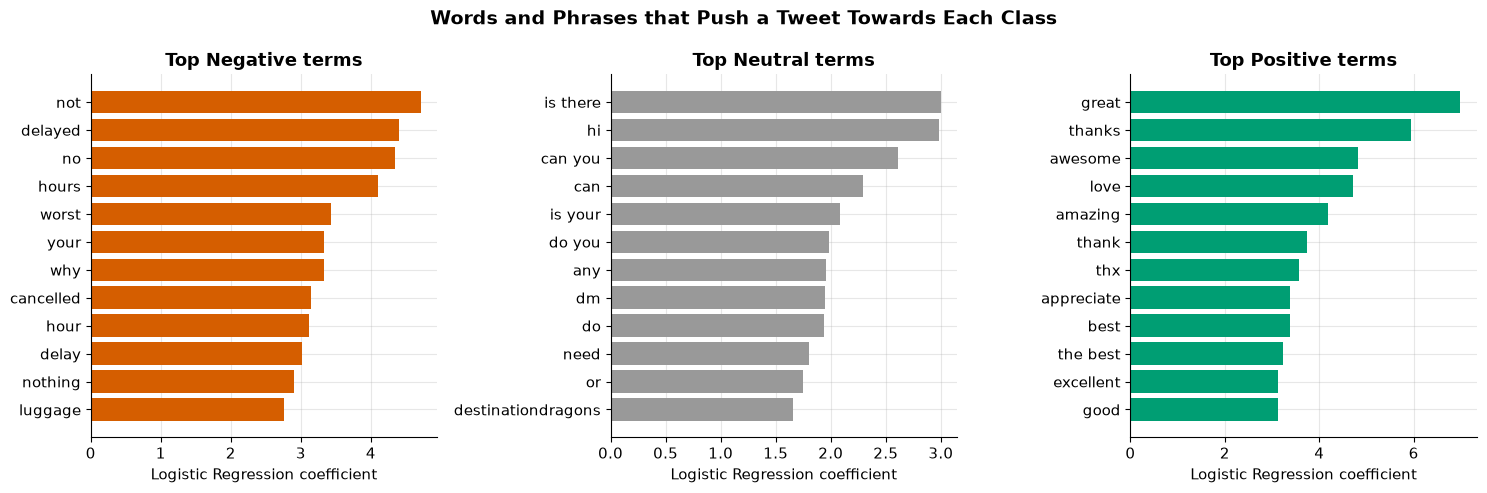

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, sentiment in zip(axes, SENTIMENT_LABELS):
    weights = coefficients[classes.index(sentiment)]
    top_idx = np.argsort(weights)[::-1][:12]
    ax.barh(vocabulary[top_idx][::-1], weights[top_idx][::-1], color=SENTIMENT_COLORS[sentiment])
    ax.set_title(f"Top {sentiment} terms")
    ax.set_xlabel("Logistic Regression coefficient")
fig.suptitle("Words and Phrases that Push a Tweet Towards Each Class", fontweight="bold", fontsize=14)
plt.tight_layout()
save_figure("top_terms_by_class.png")
plt.show()

**Interpretation:** the learned terms match intuition. Negative terms describe disruption and poor service ("delayed", "on hold", "cancelled", "worst") and include negations such as **"not"**, **"no"** and **"nothing"**, which confirms that keeping stop words was the right choice. Positive terms express thanks and praise. Neutral terms are questions and requests ("is there", "can you", "do you", "dm") plus airline campaign hashtags such as #DestinationDragons. These are learned **associations**, not causes.

## 5. Error Analysis

### 5.1 Are errors related to label uncertainty?

Each label comes with `airline_sentiment_confidence`, the annotators' agreement. If the model struggles mainly where humans also disagreed, some "errors" reflect ambiguous tweets rather than model failure.

,tweets,model_accuracy
label_confidence_band,,
<= 0.50,35,25.71
0.50-0.70,738,59.76
0.70-<1.00,65,75.38
1.00 (full agreement),2059,88.25


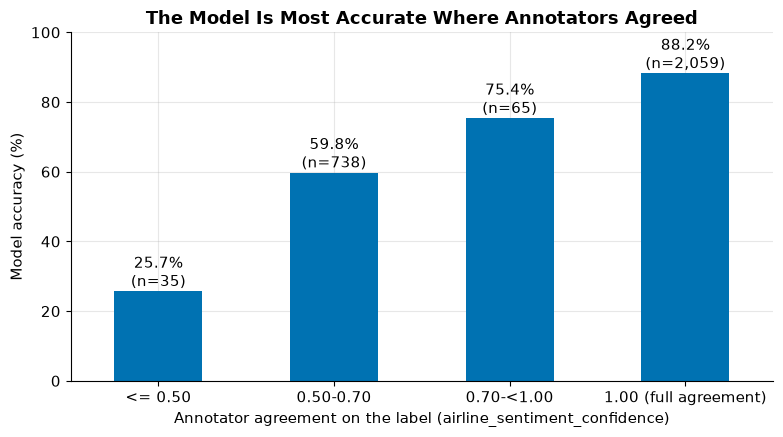

In [8]:
error_analysis = test_df[["airline", "airline_sentiment", "airline_sentiment_confidence", "text"]].copy()
error_analysis["predicted"] = tuned_predictions
error_analysis["correct"] = error_analysis["predicted"] == error_analysis["airline_sentiment"]
error_analysis["label_confidence_band"] = pd.cut(
    error_analysis["airline_sentiment_confidence"], bins=[0, 0.5, 0.7, 0.9999, 1.0],
    labels=["<= 0.50", "0.50-0.70", "0.70-<1.00", "1.00 (full agreement)"], include_lowest=True,
)

accuracy_by_confidence = error_analysis.groupby("label_confidence_band", observed=True).agg(
    tweets=("correct", "size"), model_accuracy=("correct", "mean")
)
accuracy_by_confidence["model_accuracy"] = (accuracy_by_confidence["model_accuracy"] * 100).round(2)
display(accuracy_by_confidence)

fig, ax = plt.subplots(figsize=(8, 4.5))
accuracy_by_confidence["model_accuracy"].plot(kind="bar", color=PRIMARY_COLOR, ax=ax)
ax.set_ylim(0, 100)
ax.set_ylabel("Model accuracy (%)")
ax.set_xlabel("Annotator agreement on the label (airline_sentiment_confidence)")
ax.set_title("The Model Is Most Accurate Where Annotators Agreed")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], labels=[f"{a:.1f}%\n(n={n:,})" for a, n in zip(accuracy_by_confidence["model_accuracy"], accuracy_by_confidence["tweets"])])
plt.tight_layout()
save_figure("accuracy_vs_label_confidence.png")
plt.show()

**Interpretation:** accuracy is much higher on tweets where annotators fully agreed, and drops sharply on low-agreement tweets. Part of the remaining error is therefore **label noise and genuinely ambiguous tweets**, which no text model can fully resolve.

In [9]:
# The most common error types
error_pairs = (
    error_analysis[~error_analysis["correct"]]
    .groupby(["airline_sentiment", "predicted"]).size()
    .sort_values(ascending=False).rename("errors").to_frame()
)
error_pairs["share_of_errors_pct"] = (error_pairs["errors"] / error_pairs["errors"].sum() * 100).round(2)
error_pairs

errors  share_of_errors_pct
airline_sentiment predicted                             
Negative          Neutral       186                32.01
Neutral           Negative      155                26.68
Positive          Neutral        69                11.88
                  Negative       66                11.36
Negative          Positive       53                 9.12
Neutral           Positive       52                 8.95

In [10]:
# A few misclassified examples with fully agreed labels (usernames masked)
misclassified = (error_analysis[(~error_analysis["correct"]) & (error_analysis["airline_sentiment_confidence"] == 1)]
                 .sample(6, random_state=RANDOM_STATE)[["airline_sentiment", "predicted", "text"]])
misclassified.assign(text=misclassified["text"].map(mask_user_handles))

,airline_sentiment,predicted,text
5461,Negative,Neutral,@SouthwestAir flight to San Diego is delayed per usual.. take me home!
11776,Negative,Positive,"@USAirways me too. In the future, have a better harsh weather preparedness plan. So much of your staff called out that everything snowba..."
6084,Neutral,Negative,@SouthwestAir my PR class would luv to know who's in charge of your Twitter. How many people write your tweets? #gracias
8725,Neutral,Negative,@JetBlue flight 705. EWR to FLL
12004,Negative,Neutral,"@AmericanAir continues to win: I've never missed a flight before, but a nice little quiet gate change made it possible. Sheesh."
3649,Neutral,Negative,@united Hi guys. I submitted a request for ticket/hotel reimbursement for a delayed/over night stay coming back from the Dominican. Help?


**Observation:** the examples show typical failure modes of bag-of-words models: **sarcasm** ("continues to win: I've never missed a flight before … Sheesh." is labelled Negative but reads as praise word by word), **very short replies** with almost no sentiment words ("flight 705. EWR to FLL", labelled Neutral), and **polite requests** about a problem (a reimbursement request for a delayed overnight stay), which annotators labelled Neutral but which use complaint vocabulary.

## 6. Performance by Airline (subgroup check)

,test_tweets,accuracy,macro_f1
airline,,,
US Airways,581,0.8503,0.7610
JetBlue,460,0.7696,0.7591
Southwest,493,0.7688,0.7559
United,763,0.8021,0.7283
American,513,0.8207,0.7196
Virgin America,87,0.6437,0.6204


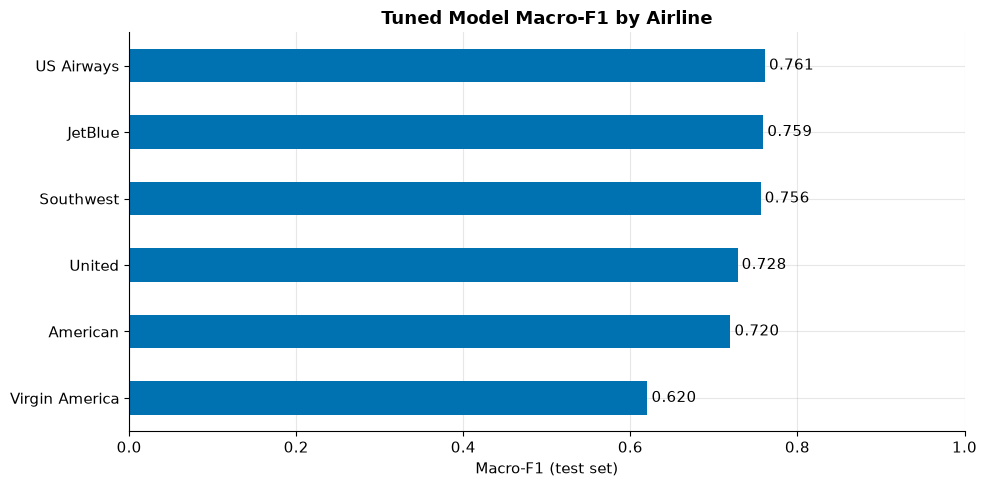

In [11]:
airline_performance = error_analysis.groupby("airline").apply(
    lambda g: pd.Series({
        "test_tweets": len(g),
        "accuracy": accuracy_score(g["airline_sentiment"], g["predicted"]),
        "macro_f1": f1_score(g["airline_sentiment"], g["predicted"], average="macro"),
    }),
    include_groups=False,
).astype({"test_tweets": int}).sort_values("macro_f1", ascending=False)
display(airline_performance.round(4))

ax = airline_performance["macro_f1"].sort_values().plot(kind="barh", color=PRIMARY_COLOR)
ax.set_xlim(0, 1)
ax.set_xlabel("Macro-F1 (test set)")
ax.set_ylabel("")
ax.set_title("Tuned Model Macro-F1 by Airline")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()

**Interpretation:** performance is broadly similar across airlines, so the model is not relying on one carrier's vocabulary. Virgin America's figure is based on few test tweets, so it is the least reliable. This is a diagnostic check, not a full fairness audit.

## 7. Conclusions

In [12]:
print(f"1. Best word-level configuration: {grid_search.best_params_}")
print(f"2. Test Macro-F1: baseline {baseline_row['macro_f1']:.4f} -> tuned {tuned_row['macro_f1']:.4f} "
      f"(accuracy {baseline_row['accuracy']:.4f} -> {tuned_row['accuracy']:.4f}).")
print(f"3. Accuracy on fully agreed labels: {accuracy_by_confidence['model_accuracy'].iloc[-1]:.1f}% "
      f"vs {accuracy_by_confidence['model_accuracy'].iloc[0]:.1f}% on the least certain labels.")
print(f"4. Largest error type: {error_pairs.index[0][0]} predicted as {error_pairs.index[0][1]} "
      f"({error_pairs['share_of_errors_pct'].iloc[0]:.1f}% of errors).")

1. Best word-level configuration: {'model__C': 2, 'model__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}
2. Test Macro-F1: baseline 0.7461 -> tuned 0.7482 (accuracy 0.7957 -> 0.7994).
3. Accuracy on fully agreed labels: 88.2% vs 25.7% on the least certain labels.
4. Largest error type: Negative predicted as Neutral (32.0% of errors).


- Tuning gives only a small gain; the next step is richer features (notebook 08).
- The model's vocabulary is sensible: disruption words and negations for Negative, thanks and praise for Positive, questions for Neutral.
- Many errors come from ambiguous or low-agreement labels and from sarcasm, which bag-of-words models cannot read.